<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 17: RNN Gradient Analysis and Gradient Clipping

### Problem Statement:
A text-generation model produces `NaN` losses midway through training because of exploding gradients. We will train a character-level text model using a high learning rate to deliberately trigger exploding gradients, track the global gradient norm, and then use gradient clipping techniques (`clipnorm` and `clipvalue`) to stabilize training.

## Setup and Data Preparation
We will download a sample public-domain text, build a character mapping, and create input/target sequences.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import urllib.request

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Download a small public-domain text (Shakespeare's Sonnets / Plays snippet)
url = "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
text = urllib.request.urlopen(url).read().decode('utf-8')[:50000] # Limit size for fast training

# Character mappings
vocab = sorted(list(set(text)))
char2idx = {char: idx for idx, char in enumerate(vocab)}
idx2char = np.array(vocab)

text_as_int = np.array([char2idx[c] for c in text])

# Prepare dataset
seq_length = 100
examples_per_epoch = len(text) // (seq_length + 1)

char_dataset = tf.data.Dataset.from_tensor_slices(text_as_int)
sequences = char_dataset.batch(seq_length + 1, drop_remainder=True)

def split_input_target(chunk):
    input_text = chunk[:-1]
    target_text = chunk[1:]
    return input_text, target_text

dataset = sequences.map(split_input_target)

BATCH_SIZE = 64
BUFFER_SIZE = 10000
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE, drop_remainder=True)

print(f"Vocabulary size: {len(vocab)}")
print(f"Number of batches: {len(list(dataset))}")

Vocabulary size: 59
Number of batches: 7


## Tasks 1 & 2: Training without clipping and logging Gradient Norms

We will define a custom training loop to capture the exact step-by-step global gradient norm. We use a high learning rate ($0.1$ or higher with SGD/Adam) to intentionally destabilize the gradients.

In [7]:
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

def build_model(vocab_size, embedding_dim=128, rnn_units=256):
    model = tf.keras.Sequential([
        Embedding(vocab_size, embedding_dim),
        SimpleRNN(rnn_units, return_sequences=True, stateful=True),
        Dense(vocab_size)
    ])
    # Specify the batch input shape by calling build on the sequential model
    model.build((BATCH_SIZE, None))
    return model

# High learning rate to provoke gradient explosion
LEARNING_RATE = 0.5

model_no_clip = build_model(len(vocab))
optimizer_no_clip = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

# Metric and history logs
grad_norms_no_clip = []
losses_no_clip = []

# Run a single training epoch or until NaN occurs
print("Training without clipping...")
# Reset states of stateful layers in Keras 3
for layer in model_no_clip.layers:
    if hasattr(layer, 'reset_state'):
        layer.reset_state()

step = 0
for x, y in dataset:
    with tf.GradientTape() as tape:
        predictions = model_no_clip(x)
        loss = loss_fn(y, predictions)

    grads = tape.gradient(loss, model_no_clip.trainable_variables)

    # Calculate global gradient norm
    global_norm = tf.linalg.global_norm(grads).numpy()
    grad_norms_no_clip.append(global_norm)
    losses_no_clip.append(loss.numpy())

    optimizer_no_clip.apply_gradients(zip(grads, model_no_clip.trainable_variables))

    if np.isnan(loss.numpy()):
        print(f"-> Training stopped at Step {step}: Loss became NaN! Global Norm at crash: {global_norm:.4f}")
        break

    step += 1
    if step % 10 == 0:
        print(f"Step {step} | Loss: {loss.numpy():.4f} | Global Norm: {global_norm:.4f}")

Training without clipping...


## Task 3: Retraining with `clipnorm` and `clipvalue` configurations

We will evaluate:
- `clipnorm=1.0`
- `clipvalue=1.0`

In [10]:
def train_with_clipping(clip_option, clip_val):
    print(f"\nTraining with {clip_option}={clip_val}...")
    model = build_model(len(vocab))

    if clip_option == 'clipnorm':
        optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE, clipnorm=clip_val)
    else:
        optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE, clipvalue=clip_val)

    grad_norms = []
    losses = []

    # Reset states of stateful layers in Keras 3
    for layer in model.layers:
        if hasattr(layer, 'reset_state'):
            layer.reset_state()

    step = 0
    for x, y in dataset:
        with tf.GradientTape() as tape:
            predictions = model(x)
            loss = loss_fn(y, predictions)

        grads = tape.gradient(loss, model.trainable_variables)
        global_norm = tf.linalg.global_norm(grads).numpy()

        # Record BEFORE optimizer clipping to observe the raw landscape
        grad_norms.append(global_norm)
        losses.append(loss.numpy())

        optimizer.apply_gradients(zip(grads, model.trainable_variables))

        if np.isnan(loss.numpy()):
            print(f"-> Stopped at Step {step}: NaN loss encountered.")
            break

        step += 1
        if step % 15 == 0:
            print(f"Step {step} | Loss: {loss.numpy():.4f} | Raw Global Norm: {global_norm:.4f}")

    return losses, grad_norms

# Train configs
losses_cn, grads_cn = train_with_clipping('clipnorm', 1.0)
losses_cv, grads_cv = train_with_clipping('clipvalue', 1.0)


Training with clipnorm=1.0...

Training with clipvalue=1.0...


## Task 4: Compare and Plot the Performance

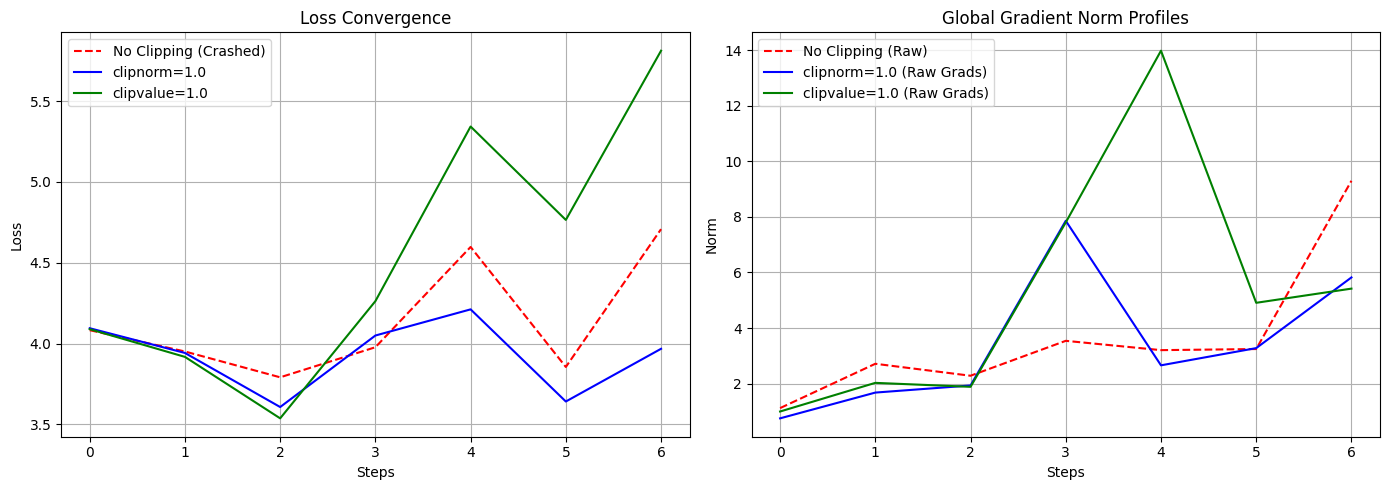

In [11]:
plt.figure(figsize=(14, 5))

# Loss comparison plot
plt.subplot(1, 2, 1)
plt.plot(losses_no_clip, label='No Clipping (Crashed)', color='red', linestyle='--')
plt.plot(losses_cn, label='clipnorm=1.0', color='blue')
plt.plot(losses_cv, label='clipvalue=1.0', color='green')
plt.title('Loss Convergence')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Gradient Norm plot
plt.subplot(1, 2, 2)
plt.plot(grad_norms_no_clip, label='No Clipping (Raw)', color='red', linestyle='--')
plt.plot(grads_cn, label='clipnorm=1.0 (Raw Grads)', color='blue')
plt.plot(grads_cv, label='clipvalue=1.0 (Raw Grads)', color='green')
plt.title('Global Gradient Norm Profiles')
plt.xlabel('Steps')
plt.ylabel('Norm')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Task 5: Recommendation & Summary

- **No Clipping**: Under high learning rates, backpropagation through time (BPTT) in RNNs accumulates gradients exponentially, triggering a rapid jump in global gradient norms leading to `NaN` losses.
- **`clipnorm`**: Restricts the entire gradient vector's magnitude globally while preserving direction. Highly recommended for standard RNN/LSTM tasks as it scales down features proportionally.
- **`clipvalue`**: Hard-clips each parameter's gradient independently. While effective, it modifies the gradient direction vector, which might lead to suboptimal optimization paths.

### Recommendation:
Use **`clipnorm = 1.0`** with adaptive learning rate optimizers (such as Adam) to prevent gradient explosion while keeping the gradient descent directions mathematically intact.